In [2]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np
import pandas as pd

# Load data
data = load_diabetes(as_frame=True)
X, y = data.data, data.target

# Train-test split
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)

# Train model
model = LinearRegression()
model.fit(Xtr, ytr)

# Coefficients with feature names
coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

# Sort by absolute value
coef_df["Abs"] = coef_df["Coefficient"].abs()
coef_df = coef_df.sort_values(by="Abs", ascending=False).drop("Abs", axis=1)

print("Feature Coefficients (sorted):")
print(coef_df)

# Predictions
y_pred = model.predict(Xte)

# Metrics
r2 = r2_score(yte, y_pred)
rmse = np.sqrt(mean_squared_error(yte, y_pred))

print("\nTest R²:", r2)
print("Test RMSE:", rmse)

Feature Coefficients (sorted):
  Feature  Coefficient
4      s1  -931.488846
8      s5   736.198859
2     bmi   542.428759
5      s2   518.062277
3      bp   347.703844
7      s4   275.317902
1     sex  -241.964362
6      s3   163.419983
9      s6    48.670657
0     age    37.904021

Test R²: 0.4526027629719195
Test RMSE: 53.85344583676593


In [4]:
import numpy as np

# Add intercept column (ones)
Xb = np.c_[np.ones(len(Xtr)), Xtr.values]

# Compute beta using Normal Equation
beta = np.linalg.inv(Xb.T @ Xb) @ Xb.T @ ytr.values

# Intercept and coefficients
intercept = beta[0]
coefficients = beta[1:]

print("Intercept:", intercept)
print("Coefficients:", coefficients)

# Compare with sklearn
print("\nSklearn Intercept:", model.intercept_)
print("Sklearn Coefficients:", model.coef_)

Intercept: 151.34560453986
Coefficients: [  37.90402135 -241.96436231  542.42875852  347.70384391 -931.48884588
  518.06227698  163.41998299  275.31790158  736.1988589    48.67065743]

Sklearn Intercept: 151.34560453985995
Sklearn Coefficients: [  37.90402135 -241.96436231  542.42875852  347.70384391 -931.48884588
  518.06227698  163.41998299  275.31790158  736.1988589    48.67065743]


In [5]:
# Copy dataset
X_cat = X.copy()

# Create categorical feature from BMI
X_cat['bmi_cat'] = pd.qcut(X_cat['bmi'], q=3, labels=['low', 'mid', 'high'])

# One-hot encoding (drop first)
X_cat = pd.get_dummies(X_cat, columns=['bmi_cat'], drop_first=True)

# Train-test split again
Xtr_c, Xte_c, ytr_c, yte_c = train_test_split(X_cat, y, test_size=0.2, random_state=42)

# Train model
model_cat = LinearRegression()
model_cat.fit(Xtr_c, ytr_c)

# Coefficients
coef_cat = pd.DataFrame({
    "Feature": X_cat.columns,
    "Coefficient": model_cat.coef_
})

print("New Coefficients with Categorical Feature:")
print(coef_cat)

# Interpretation
print("\nInterpretation:")
print("bmi_cat_mid → difference from 'low'")
print("bmi_cat_high → difference from 'low'")

New Coefficients with Categorical Feature:
         Feature  Coefficient
0            age    44.213081
1            sex  -234.015436
2            bmi   576.980844
3             bp   348.690244
4             s1  -982.156424
5             s2   572.718689
6             s3   187.200176
7             s4   279.310700
8             s5   758.901115
9             s6    48.394294
10   bmi_cat_mid   -12.114721
11  bmi_cat_high    -6.762463

Interpretation:
bmi_cat_mid → difference from 'low'
bmi_cat_high → difference from 'low'


In [3]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np
import pandas as pd

# Load data
data = load_diabetes(as_frame=True)
X, y = data.data, data.target
Xtr, Xte, ytr, yte = train_test_split(
    X, y, test_size=0.2, random_state=42)

print("="*70)
print("PROBLEM 6: Fit and read the coefficients")
print("="*70)

# Fit multiple linear regression
model = LinearRegression()
model.fit(Xtr, ytr)

# Get feature names and coefficients
feature_names = X.columns.tolist()
coefficients = model.coef_

# Create a dataframe and sort by absolute value
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients,
    'Abs_Coefficient': np.abs(coefficients)
})
coef_df = coef_df.sort_values('Abs_Coefficient', ascending=False)

print("\nFeature Coefficients (sorted by absolute value):")
print("-" * 50)
for idx, row in coef_df.iterrows():
    print(f"{row['Feature']:20s}: {row['Coefficient']:10.4f}")

# Calculate test set R² and RMSE
y_pred = model.predict(Xte)
r2 = r2_score(yte, y_pred)
rmse = np.sqrt(mean_squared_error(yte, y_pred))

print("\n" + "-" * 50)
print(f"Test R²:   {r2:.4f}")
print(f"Test RMSE: {rmse:.4f}")

print("\n" + "="*70)
print("PROBLEM 7: The normal equation from scratch")
print("="*70)

# Implement β = (X'X)^(-1)X'y with NumPy
# Add intercept column
Xtr_with_intercept = np.c_[np.ones(len(Xtr)), Xtr.values]
ytr_values = ytr.values

# Calculate beta using normal equation
# β = (X'X)^(-1)X'y
beta = np.linalg.inv(Xtr_with_intercept.T @ Xtr_with_intercept) @ Xtr_with_intercept.T @ ytr_values

print("\nCoefficients from Normal Equation:")
print("-" * 50)
print(f"Intercept: {beta[0]:.4f}")
for i, feature_name in enumerate(feature_names):
    print(f"{feature_name:20s}: {beta[i+1]:10.4f}")

# Compare with sklearn's coefficients
print("\nComparison with scikit-learn:")
print("-" * 50)
print(f"sklearn intercept:       {model.intercept_:.4f}")
print(f"Normal equation intercept: {beta[0]:.4f}")
print(f"\nsklearn coefficients match Normal equation: {np.allclose(model.coef_, beta[1:])}")

print("\n" + "="*70)
print("PROBLEM 8: Add a categorical feature")
print("="*70)

# Create a copy of the data
X_binned = X.copy()

# Bin one of the numeric features (let's use the first feature 'age')
# into 'low', 'mid', 'high' categories
age_feature = X_binned.iloc[:, 0]  # First feature
bins = 3
X_binned['age_binned'] = pd.cut(age_feature, bins=bins, labels=['low', 'mid', 'high'])

print("\nOriginal data shape:", X.shape)
print("New data shape:", X_binned.shape)
print("\nFirst 10 rows with new binned feature:")
print(X_binned.head(10))

# One-hot encode the categorical feature (avoiding dummy trap)
X_binned_encoded = pd.get_dummies(X_binned, columns=['age_binned'], drop_first=True)

print("\nAfter one-hot encoding (dropping first category to avoid dummy trap):")
print("Shape:", X_binned_encoded.shape)
print("New columns:", X_binned_encoded.columns.tolist())

# Split data and fit model with binned features
Xtr_binned, Xte_binned, ytr_binned, yte_binned = train_test_split(
    X_binned_encoded, y, test_size=0.2, random_state=42)

model_binned = LinearRegression()
model_binned.fit(Xtr_binned, ytr_binned)

# Compare coefficients relative to baseline
y_pred_binned = model_binned.predict(Xte_binned)
r2_binned = r2_score(yte_binned, y_pred_binned)
rmse_binned = np.sqrt(mean_squared_error(yte_binned, y_pred_binned))

print("\n" + "-" * 50)
print("Model Performance Comparison:")
print("-" * 50)
print(f"Original Model - Test R²: {r2:.4f}, Test RMSE: {rmse:.4f}")
print(f"Binned Model   - Test R²: {r2_binned:.4f}, Test RMSE: {rmse_binned:.4f}")

print("\nCoefficients for binned categorical features:")
print("-" * 50)
categorical_cols = [col for col in X_binned_encoded.columns if 'binned' in col]
for col in categorical_cols:
    idx = X_binned_encoded.columns.get_loc(col)
    print(f"{col:25s}: {model_binned.coef_[idx]:10.4f}")

print("\n" + "="*70)

PROBLEM 6: Fit and read the coefficients

Feature Coefficients (sorted by absolute value):
--------------------------------------------------
s1                  :  -931.4888
s5                  :   736.1989
bmi                 :   542.4288
s2                  :   518.0623
bp                  :   347.7038
s4                  :   275.3179
sex                 :  -241.9644
s3                  :   163.4200
s6                  :    48.6707
age                 :    37.9040

--------------------------------------------------
Test R²:   0.4526
Test RMSE: 53.8534

PROBLEM 7: The normal equation from scratch

Coefficients from Normal Equation:
--------------------------------------------------
Intercept: 151.3456
age                 :    37.9040
sex                 :  -241.9644
bmi                 :   542.4288
bp                  :   347.7038
s1                  :  -931.4888
s2                  :   518.0623
s3                  :   163.4200
s4                  :   275.3179
s5                  :  

Slope: 87.18097620201259 Intercept: 2.142770851531786


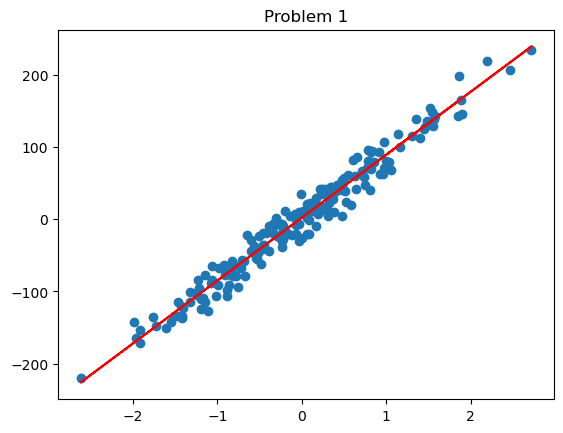

R2: 0.9662908496470797


TypeError: got an unexpected keyword argument 'squared'

In [2]:
# ==============================
# COMMON IMPORTS
# ==============================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_regression, load_diabetes
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.model_selection import train_test_split, GridSearchCV, learning_curve
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif

# ==============================
# PART 1 — SIMPLE LINEAR REGRESSION
# ==============================

# Dataset
X, y = make_regression(n_samples=200, n_features=1, noise=15.0, random_state=42)

# ------------------------------
# Problem 1
# ------------------------------
model = LinearRegression().fit(X, y)
print("Slope:", model.coef_[0], "Intercept:", model.intercept_)

plt.scatter(X, y)
plt.plot(X, model.predict(X), color='red')
plt.title("Problem 1")
plt.show()

# ------------------------------
# Problem 2
# ------------------------------
pred = model.predict(X)
print("R2:", r2_score(y, pred))
print("RMSE:", mean_squared_error(y, pred, squared=False))
print("MAE:", mean_absolute_error(y, pred))

res = y - pred
rmse = np.sqrt(np.mean(res**2))
r2 = 1 - np.sum(res**2) / np.sum((y - y.mean())**2)
print("Manual RMSE:", rmse, "Manual R2:", r2)

# ------------------------------
# Problem 3 (OLS from scratch)
# ------------------------------
x = X.ravel()
slope = np.sum((x - x.mean()) * (y - y.mean())) / np.sum((x - x.mean())**2)
intercept = y.mean() - slope * x.mean()
print("OLS slope:", slope, "Intercept:", intercept)

# ------------------------------
# Problem 4 (Gradient Descent)
# ------------------------------
Xs = ((X - X.mean()) / X.std()).ravel()
w, b, lr = 0, 0, 0.01
hist = []
n = len(y)

for _ in range(1000):
    yhat = w * Xs + b
    err = yhat - y
    dw = (2/n) * np.sum(err * Xs)
    db = (2/n) * np.sum(err)
    w -= lr * dw
    b -= lr * db
    hist.append(np.mean(err**2))

plt.plot(hist)
plt.title("Cost Curve")
plt.show()

# ------------------------------
# Problem 5 (Residuals)
# ------------------------------
res = y - model.predict(X)

plt.subplot(1,2,1)
plt.scatter(model.predict(X), res)
plt.axhline(0, color='red')

plt.subplot(1,2,2)
plt.hist(res)

plt.show()


# ==============================
# PART 2 — MULTIPLE REGRESSION
# ==============================

data = load_diabetes(as_frame=True)
X, y = data.data, data.target

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)

# ------------------------------
# Problem 6
# ------------------------------
m = LinearRegression().fit(Xtr, ytr)

for name, coef in sorted(zip(X.columns, m.coef_), key=lambda x: -abs(x[1])):
    print(name, coef)

pred = m.predict(Xte)
print("Test R2:", r2_score(yte, pred))
print("RMSE:", mean_squared_error(yte, pred, squared=False))

# ------------------------------
# Problem 7 (Normal Equation)
# ------------------------------
Xb = np.c_[np.ones(len(Xtr)), Xtr.values]
beta = np.linalg.inv(Xb.T @ Xb) @ Xb.T @ ytr.values
print("Intercept:", beta[0])
print("Coefficients:", beta[1:])

# ------------------------------
# Problem 8 (Categorical)
# ------------------------------
Xc = X.copy()
Xc['bmi_cat'] = pd.qcut(X['bmi'], 3, labels=['low','mid','high'])
Xc = pd.get_dummies(Xc, drop_first=True)

LinearRegression().fit(Xc, y)

# ------------------------------
# Problem 9 (VIF)
# ------------------------------
X_vals = X.values
vif_scores = [(X.columns[i], vif(X_vals, i)) for i in range(X.shape[1])]
print(sorted(vif_scores, key=lambda x: -x[1]))

# ------------------------------
# Problem 10 (R2 vs Adjusted R2)
# ------------------------------
r2s, adj = [], []
n = len(ytr)

for k in range(1, len(X.columns)+1):
    cols = X.columns[:k]
    mk = LinearRegression().fit(Xtr[cols], ytr)
    r2 = mk.score(Xtr[cols], ytr)
    r2s.append(r2)
    adj.append(1 - (1-r2)*(n-1)/(n-k-1))

plt.plot(r2s, label="R2")
plt.plot(adj, label="Adjusted R2")
plt.legend()
plt.show()


# ==============================
# PART 3 — RIDGE
# ==============================

# ------------------------------
# Problem 11
# ------------------------------
for a in [0.1, 1, 10, 100]:
    pipe = make_pipeline(StandardScaler(), Ridge(alpha=a))
    pipe.fit(Xtr, ytr)
    coefs = pipe.named_steps['ridge'].coef_
    print(a, np.sum(np.abs(coefs)))

# ------------------------------
# Problem 12 (Ridge trace)
# ------------------------------
scaler = StandardScaler().fit(Xtr)
Xs = scaler.transform(Xtr)

alphas = np.logspace(-2, 4, 50)
paths = np.array([Ridge(alpha=a).fit(Xs, ytr).coef_ for a in alphas])

for i in range(paths.shape[1]):
    plt.plot(alphas, paths[:, i])

plt.xscale('log')
plt.show()

# ------------------------------
# Problem 13 (GridSearch)
# ------------------------------
pipe = make_pipeline(StandardScaler(), Ridge())
grid = GridSearchCV(pipe, {'ridge__alpha': np.logspace(-3,3,20)}, cv=5)
grid.fit(Xtr, ytr)

print("Best alpha:", grid.best_params_)
pred = grid.predict(Xte)
print("RMSE:", mean_squared_error(yte, pred, squared=False))

# ------------------------------
# Problem 14 (Multicollinearity)
# ------------------------------
rng = np.random.default_rng(42)
x1 = rng.normal(size=500)
x2 = x1 + rng.normal(scale=0.01, size=500)

Xc = np.c_[x1, x2]
yc = 3*x1 + rng.normal(size=500)

print("OLS:", LinearRegression().fit(Xc, yc).coef_)
print("Ridge:", Ridge(alpha=1).fit(Xc, yc).coef_)


# ==============================
# PART 4 — LASSO
# ==============================

# ------------------------------
# Problem 15
# ------------------------------
pipe = make_pipeline(StandardScaler(), Lasso(alpha=1.0))
pipe.fit(Xtr, ytr)

coefs = pipe.named_steps['lasso'].coef_
print("Dropped:", np.sum(coefs == 0))

# ------------------------------
# Problem 16 (Lasso path)
# ------------------------------
from sklearn.linear_model import lasso_path

Xs = StandardScaler().fit_transform(Xtr)
alphas = np.logspace(-3,1,50)

_, coefs_path, _ = lasso_path(Xs, ytr, alphas=alphas)

for i in range(coefs_path.shape[0]):
    plt.plot(alphas, coefs_path[i])

plt.xscale('log')
plt.show()

# ------------------------------
# Problem 17 (LassoCV)
# ------------------------------
from sklearn.linear_model import LassoCV

lasso_cv = LassoCV(cv=5, max_iter=10000)
lasso_cv.fit(Xs, ytr)

print("Best alpha:", lasso_cv.alpha_)
print("Selected features:", np.sum(lasso_cv.coef_ != 0))

# ------------------------------
# Problem 18 (Comparison)
# ------------------------------
from sklearn.linear_model import RidgeCV, ElasticNetCV

X2, y2 = make_regression(n_samples=400, n_features=50, n_informative=8, noise=10, random_state=42)
Xtr2, Xte2, ytr2, yte2 = train_test_split(X2, y2, test_size=0.25, random_state=42)

models = {
    "Ridge": RidgeCV(alphas=np.logspace(-2,3,30)),
    "Lasso": LassoCV(cv=5, max_iter=10000),
    "ElasticNet": ElasticNetCV(l1_ratio=[0.2,0.5,0.8], cv=5)
}

for name, mdl in models.items():
    mdl.fit(Xtr2, ytr2)
    rmse = mean_squared_error(yte2, mdl.predict(Xte2), squared=False)
    nz = np.sum(mdl.coef_ != 0)
    print(name, "RMSE:", rmse, "Non-zero:", nz)


# ==============================
# PART 5 — CAPSTONE
# ==============================

# ------------------------------
# Problem 19 (Pipeline)
# ------------------------------
best = {}

for name, model in {"ridge": Ridge(), "lasso": Lasso(max_iter=10000)}.items():
    pipe = make_pipeline(StandardScaler(), model)
    grid = GridSearchCV(pipe, {f"{name}__alpha": np.logspace(-3,3,20)}, cv=5)
    grid.fit(Xtr, ytr)

    pred = grid.predict(Xte)
    rmse = mean_squared_error(yte, pred, squared=False)
    r2 = r2_score(yte, pred)

    best[name] = (grid.best_params_, rmse, r2)

print(best)

# ------------------------------
# Problem 20 (Learning Curve)
# ------------------------------
for label, est in [("OLS", LinearRegression()), ("Ridge", Ridge(alpha=10))]:
    pipe = make_pipeline(StandardScaler(), est)
    sizes, train_scores, val_scores = learning_curve(
        pipe, X, y, cv=5, scoring="neg_root_mean_squared_error",
        train_sizes=np.linspace(0.1,1.0,8)
    )

    plt.plot(sizes, -train_scores.mean(axis=1), '--', label=f"{label} Train")
    plt.plot(sizes, -val_scores.mean(axis=1), label=f"{label} Val")

plt.legend()
plt.xlabel("Training Size")
plt.ylabel("RMSE")
plt.show()